In [1]:
import os

def show_inputs(depth=4, max_files_per_dir=6):
    """Print what is attached under /kaggle/input - check it before trusting the rest."""
    root0 = os.environ.get("SAT_INPUT", "/kaggle/input")
    for root, dirs, files in os.walk(root0):
        dirs[:] = sorted(d for d in dirs if not d.startswith("."))
        level = root.replace(root0, "").count(os.sep)
        if level > depth:
            dirs[:] = []
            continue
        print("  " * level + root + "/")
        for fn in sorted(files)[:max_files_per_dir]:
            print("  " * level + "  " + fn)
        if len(files) > max_files_per_dir:
            print("  " * level + f"  ... +{len(files) - max_files_per_dir} more files")

show_inputs()

/kaggle/input/
  /kaggle/input/datasets/
    /kaggle/input/datasets/rollsroyce1/
      /kaggle/input/datasets/rollsroyce1/sat-ext/
        /kaggle/input/datasets/rollsroyce1/sat-ext/sat_ext/
          README.md
          analysis.py
          audit.py
          config.py
          dataset.py
          dota.py
          ... +11 more files
      /kaggle/input/datasets/rollsroyce1/sat-results-07a/
        yolo11s.pt
        yolo26n.pt
        /kaggle/input/datasets/rollsroyce1/sat-results-07a/results/
        /kaggle/input/datasets/rollsroyce1/sat-results-07a/results_07A/
        /kaggle/input/datasets/rollsroyce1/sat-results-07a/weights/
          grouped__YOLO11s-1024__s42_best.pt
          grouped__YOLO11s-1024__s43_best.pt
          grouped__YOLO11s-1024__s44_best.pt
          grouped__YOLO11s-1280__s42_best.pt
          grouped__YOLO11s-1280__s43_best.pt
          grouped__YOLO11s-1280__s44_best.pt
      /kaggle/input/datasets/rollsroyce1/sat-results-e/
        yolo11n.pt
        yol

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
INPUT_ROOT = os.environ.get("SAT_INPUT", "/kaggle/input")

def _find_code_root():
    for root, dirs, files in os.walk(INPUT_ROOT):
        if {"config.py", "audit.py", "metrics.py", "infer.py"} <= set(files):
            return root
    return None

CODE_ROOT = os.environ.get("SAT_CODE") or _find_code_root()
assert CODE_ROOT, "sat_ext code folder not found - Add Input -> your 'sat-ext' code Dataset"
sys.path.insert(0, CODE_ROOT)
print("CODE_ROOT:", CODE_ROOT)

import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 70)
import config as cfg, utils
utils.ensure_dirs(); utils.set_seed(cfg.SEED)
print("work dir:", cfg.WORK_DIR, "| smoke test:", cfg.SMOKE)

CODE_ROOT: /kaggle/input/datasets/rollsroyce1/sat-ext/sat_ext
work dir: /kaggle/working | smoke test: False


materialized 'grouped' (f7cee44b1365) -> /kaggle/working/data_grouped  images {'train': 984, 'val': 80, 'test': 82}
grouped__YOLO11s-1024__s42 | 50 background false positives at conf >= 0.25
download: /kaggle/working/fp_review.zip 8.5 MB


/kaggle/working/fp_review.zip

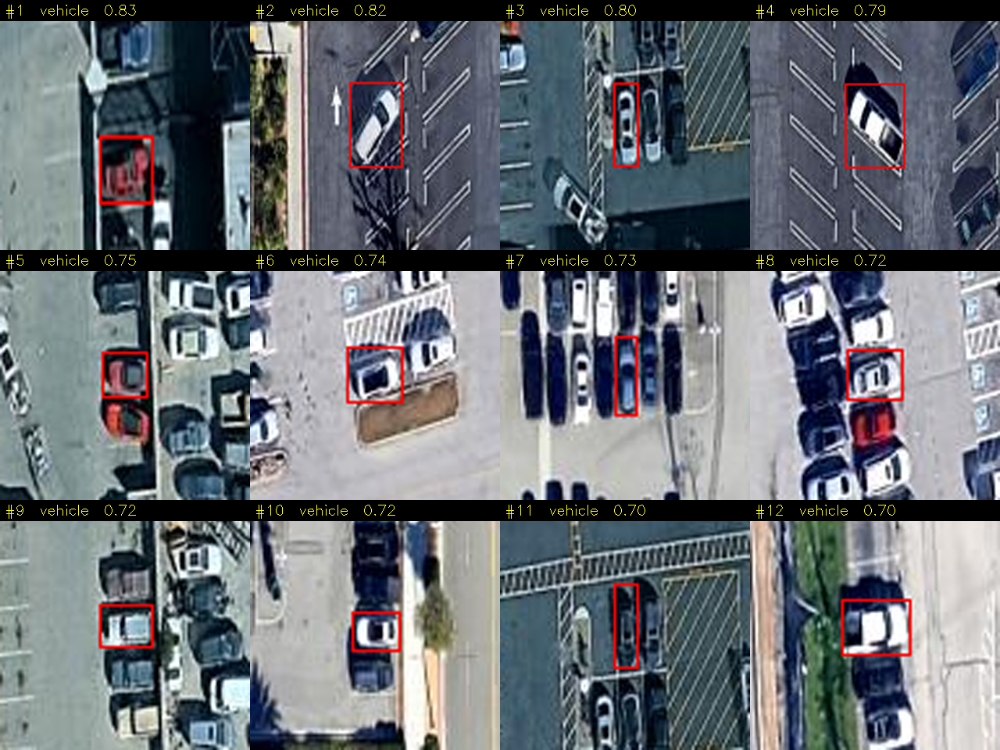

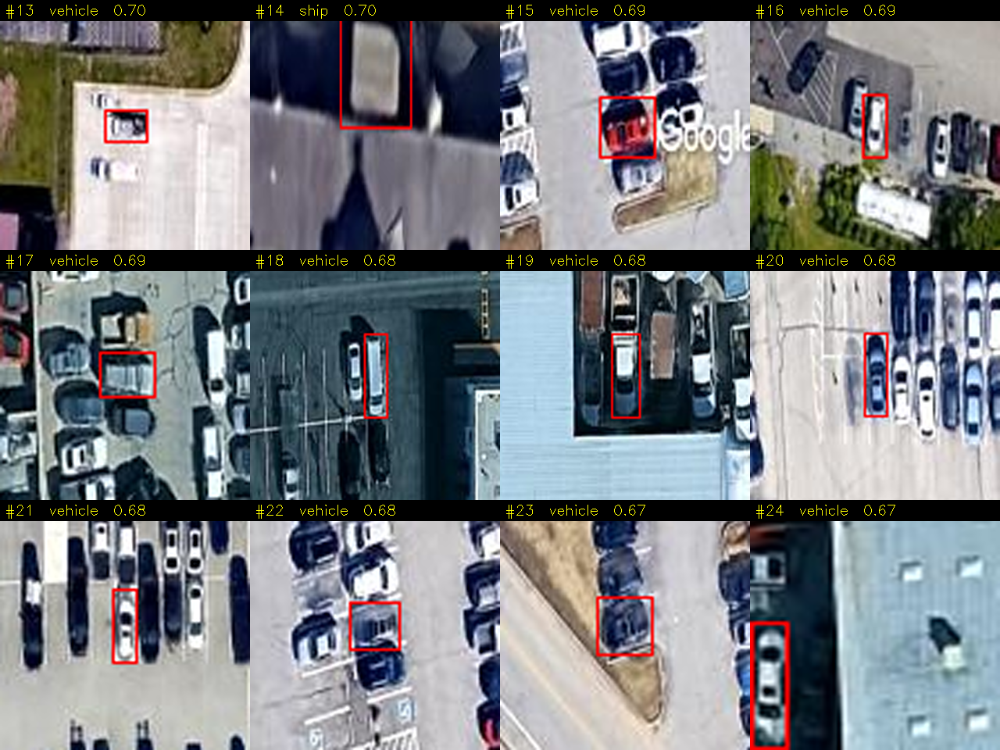

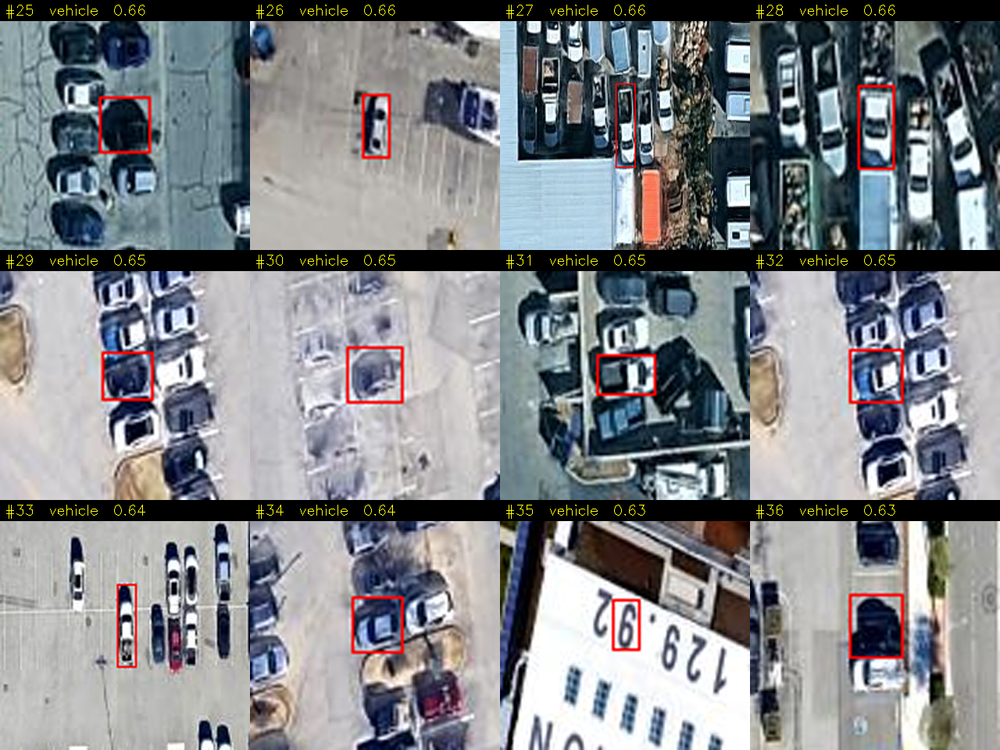

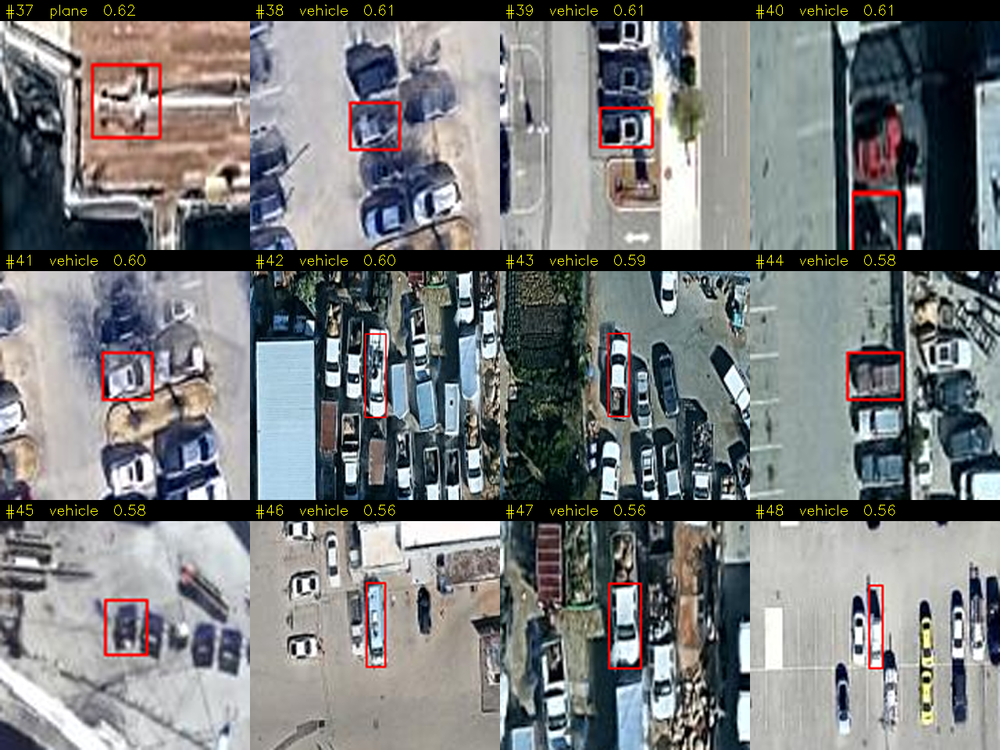

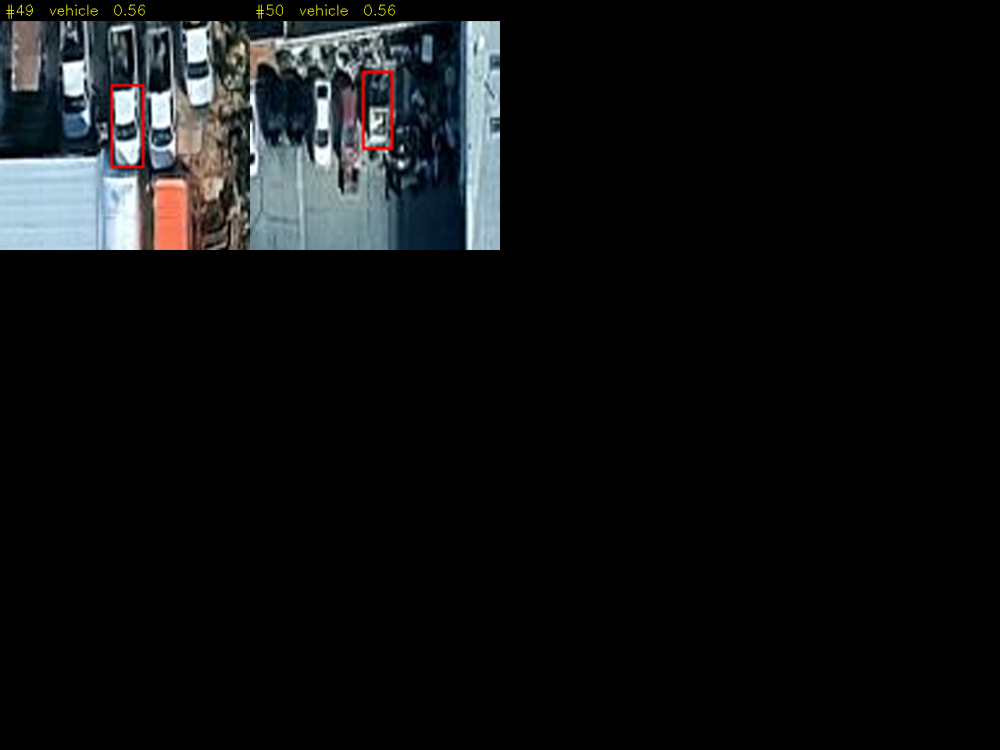

In [3]:
import numpy as np, cv2, analysis, report, metrics, dataset as ds
os.makedirs(report.PAPER_DIR, exist_ok=True)
runs = {}
for p in utils.find_files("eval_test.json"):     # only folders that also hold the saved detections
    if utils.dets_path(os.path.dirname(p), "standard"):
        runs[utils.load_json(p)["run_id"]] = os.path.dirname(p)
RID, dets = None, None
for r in ["grouped__YOLO11s-1024__s42", "grouped__YOLO11s__s42", "grouped__YOLO11m__s42"]:
    if r in runs and analysis._dets(runs[r], "standard") is not None:
        RID, dets = r, analysis._dets(runs[r], "standard"); break
    if r in runs:
        print("no saved detections for", r, "-> trying the next model")
assert RID, "attach sat-results-e (grouped YOLO11s seed 42, with its results/ folder)"
gt = analysis._gt_for("grouped")
gb = {}
for a in gt["annotations"]:
    gb.setdefault(a["image_id"], []).append(a["bbox"])
fps = []
for d in dets:
    if d["score"] < cfg.OP_CONF:
        continue
    g = np.array(gb.get(d["image_id"], []), float).reshape(-1, 4)
    iou = metrics._iou_xywh(np.array([d["bbox"]], float), g)[0] if len(g) else np.zeros(0)
    if not len(iou) or iou.max() < 0.1:
        fps.append(d)
fps = sorted(fps, key=lambda d: -d["score"])[:50]
names = {i["id"]: i["file_name"] for i in gt["images"]}
info = ds.materialize("grouped")
CELL, COLS, PER_PAGE = 320, 4, 12        # bigger crops, 12 per page -> easier to judge
tiles = []
for k, d in enumerate(fps, 1):
    im = cv2.imread(os.path.join(info["images"]["test"], names[d["image_id"]]))
    x, y, w, h = d["bbox"]
    r = max(48, 1.5 * max(w, h))
    cx, cy = x + w / 2, y + h / 2
    x0, y0 = int(max(0, cx - r)), int(max(0, cy - r))
    x1, y1 = int(min(im.shape[1], cx + r)), int(min(im.shape[0], cy + r))
    crop = im[y0:y1, x0:x1].copy()
    cv2.rectangle(crop, (int(x - x0), int(y - y0)), (int(x + w - x0), int(y + h - y0)), (0, 0, 255), 1)
    crop = cv2.resize(crop, (CELL, CELL), interpolation=cv2.INTER_CUBIC)
    cv2.rectangle(crop, (0, 0), (CELL, 26), (0, 0, 0), -1)
    cv2.putText(crop, f"#{k}  {cfg.CLASSES[d['category_id'] - 1]}  {d['score']:.2f}", (6, 19),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 1)
    tiles.append(crop)
pages = []
for p in range(0, len(tiles), PER_PAGE):
    t = tiles[p:p + PER_PAGE] + [np.zeros((CELL, CELL, 3), np.uint8)] * (PER_PAGE - len(tiles[p:p + PER_PAGE]))
    page = np.vstack([np.hstack(t[r * COLS:(r + 1) * COLS]) for r in range(PER_PAGE // COLS)])
    fn = os.path.join(report.PAPER_DIR, f"fp_review_page{p // PER_PAGE + 1}.png")
    cv2.imwrite(fn, page); pages.append(fn)
import pandas as pd
pd.DataFrame([dict(id=k, file_name=names[d["image_id"]], cls=cfg.CLASSES[d["category_id"] - 1], score=round(d["score"], 3),
                   bbox=[round(v, 1) for v in d["bbox"]]) for k, d in enumerate(fps, 1)]).to_csv(
    os.path.join(report.PAPER_DIR, "fp_review_list.csv"), index=False)
print(RID, "|", len(fps), "background false positives at conf >=", cfg.OP_CONF)
import zipfile, shutil
zp = os.path.join(cfg.WORK_DIR, "fp_review.zip")      # ONE small file: the 5 pages + the list
with zipfile.ZipFile(zp, "w") as z:
    for fn in pages + [os.path.join(report.PAPER_DIR, "fp_review_list.csv")]:
        z.write(fn, os.path.basename(fn))
shutil.rmtree(info["root"], ignore_errors=True)       # copied images are not needed in the output
print("download:", zp, round(os.path.getsize(zp) / 1e6, 1), "MB")
try:
    from IPython.display import Image, display, FileLink
    display(FileLink("fp_review.zip"))                # click to download (interactive session)
    for fn in pages:
        display(Image(fn))
except ImportError:
    print(pages)

In [4]:
# >>> Look at EVERY page above. Type the #numbers YOU judged, then run this cell. <<<
MISSING = []     # crops showing a REAL plane / ship / vehicle that has no label (annotation miss)
UNSURE = []      # crops you cannot decide
n = len(fps)
assert set(MISSING) | set(UNSURE) <= set(range(1, n + 1)), "numbers must be between 1 and %d" % n
assert not set(MISSING) & set(UNSURE), "a crop cannot be both MISSING and UNSURE"
print("reviewed", n, "| missing:", sorted(MISSING), "| unsure:", sorted(UNSURE))
lst = pd.read_csv(os.path.join(report.PAPER_DIR, "fp_review_list.csv"))
lst["verdict"] = ["missing_label" if i in MISSING else "unsure" if i in UNSURE else "true_false_positive" for i in lst.id]
lst.to_csv(os.path.join(report.PAPER_DIR, "fp_review_list.csv"), index=False)
print(lst.groupby(["cls", "verdict"]).size().unstack(fill_value=0))
t = pd.DataFrame([dict(Model=RID, Reviewed=n, Missing_label=len(MISSING), Unsure=len(UNSURE),
                       True_false_positive=n - len(MISSING) - len(UNSURE),
                       Missing_share=f"{100 * len(MISSING) / max(n, 1):.0f}%")])
report.save(t, "T16_label_quality", f"Manual review of the {n} highest-confidence background false positives of {RID} on the "
            "grouped test split: share that are real but unlabelled objects (annotation misses).")

reviewed 50 | missing: [] | unsure: []
verdict  true_false_positive
cls                         
plane                      1
ship                       1
vehicle                   48

### T16_label_quality: Manual review of the 50 highest-confidence background false positives of grouped__YOLO11s-1024__s42 on the grouped test split: share that are real but unlabelled objects (annotation misses).
                     Model  Reviewed  Missing_label  Unsure  True_false_positive Missing_share
grouped__YOLO11s-1024__s42        50              0       0                   50            0%
